# Project Part 4

- Team 7
- Henry Lai, Hirna Derege, Fatimah Abdullahi, Kimi Yokoyama
- Smart Healthcare and Lifestyle Prediction Dataset
- Target Variable: Heart_Disease
- Main Modeling Goal: Train a model to predict heart disease using patient medical records, free from the biases that have historically affected medical diagnosis in the US. The goal is for predictions to be based purely on clinical indicators rather than subjective human judgment.
- New Changes:
- In Part 4, the preprocessing pipeline was corrected to fix two data leakage issues. Target balance was formally checked and a subgroup analysis by gender was conducted to address fairness concerns.
- On the modeling side, Naive Bayes was replaced with Decision Tree and SVM to create a more deliberate linear, tree-based, and margin-based progression, with Random Forest added as the ensemble model. Evaluation was also expanded beyond accuracy to include ROC-AUC and F1-score, supported by ROC curve and confusion matrix visuals across all models.

# Data and Feature Updates

In [ ]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('smart_healthcare_dataset.csv')

In [ ]:
# Class Imbalance Check
print(df['heart_disease'].value_counts())
print(df['heart_disease'].value_counts(normalize=True))

heart_disease
0    3501
1    1499
Name: count, dtype: int64
heart_disease
0    0.7002
1    0.2998
Name: proportion, dtype: float64


In [ ]:
# Subgroup Check
for gender_val, group in df.groupby('gender'):
    label = 'Male' if gender_val == 0 else 'Female'
    print(f"{label}: heart_disease rate = {group['heart_disease'].mean():.2%}")

Male: heart_disease rate = 30.41%
Female: heart_disease rate = 29.55%


Updates:
- StandardScaler was applied to all continuous numerical features (age, bmi, blood_pressure, cholesterol, glucose, health_risk_score) to normalize their distributions to zero mean and unit variance. This is necessary for our logistic regression, which are sensitive to differences in feature magnitude.  the scaler was fit exclusively on the training set and then applied to the test set.
- For class imbalance: The target variable heart_disease was found to be moderately imbalanced at 70.0% negative and 30.0% positive. The train/test split was stratified using stratify=y to preserve this ratio across both sets. Additionally, we'll add class_weight='balanced' in training to penalize misclassification of the minority class more heavily.
- A subgroup analysis by gender revealed heart disease rates of 30.41% for female patients and 29.55% for male patients, a difference of less than 1%. This suggests the dataset is balanced with respect to gender and the target variable, reducing the likelihood of gender-based bias in model predictions. However, the dataset lacks other demographic variables such as race, ethnicity, and socioeconomic status, which limits the scope of a comprehensive fairness evaluation. Subgroup performance remains a limitation of this analysis.

# Model Improvement and Comparison

**Model 1: (Updated Logistic Regression from Part 3)**

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

# Label encode gender before splitting
le = LabelEncoder()
df['gender'] = le.fit_transform(df['gender'])

# Features and target (health_risk_score removed)
features = ['age', 'gender', 'bmi', 'exercise_level', 'smoking', 'alcohol',
            'blood_pressure', 'cholesterol', 'glucose', 'fatigue',
            'chest_pain', 'dizziness', 'diabetes', 'stroke']

X = df[features]
y = df['heart_disease']

# Train/test split (stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale all features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Model 1: Logistic Regression (Baseline)
lr = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
lr.fit(X_train_scaled, y_train)
lr_preds = lr.predict(X_test_scaled)
lr_probs = lr.predict_proba(X_test_scaled)[:, 1]

print("Logistic Regression")
print(f"Accuracy: {accuracy_score(y_test, lr_preds):.4f}")
print(classification_report(y_test, lr_preds))
print(f"ROC-AUC: {roc_auc_score(y_test, lr_probs):.4f}")

Logistic Regression
Accuracy: 0.9910
              precision    recall  f1-score   support

           0       1.00      0.99      0.99       700
           1       0.97      1.00      0.99       300

    accuracy                           0.99      1000
   macro avg       0.99      0.99      0.99      1000
weighted avg       0.99      0.99      0.99      1000

ROC-AUC: 0.9996


**Model 2: Decision Tree**

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, roc_auc_score

dt = DecisionTreeClassifier(class_weight='balanced', max_depth=5, random_state=42)
dt.fit(X_train, y_train)
y_pred_dt = dt.predict(X_test)
y_prob_dt = dt.predict_proba(X_test)[:, 1]

print("Decision Tree")
print(classification_report(y_test, y_pred_dt))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_dt))

Decision Tree
              precision    recall  f1-score   support

           0       0.99      0.95      0.97       700
           1       0.89      0.98      0.93       300

    accuracy                           0.96      1000
   macro avg       0.94      0.96      0.95      1000
weighted avg       0.96      0.96      0.96      1000

ROC-AUC: 0.9910238095238095


**Model 3: SVM**

In [ ]:
from sklearn.svm import SVC

svm = SVC(kernel='rbf', class_weight='balanced', probability=True, random_state=42)
svm.fit(X_train, y_train)
y_pred_svm = svm.predict(X_test)
y_prob_svm = svm.predict_proba(X_test)[:, 1]

print("SVM")
print(classification_report(y_test, y_pred_svm))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_svm))

SVM
              precision    recall  f1-score   support

           0       0.99      0.93      0.96       700
           1       0.85      0.98      0.91       300

    accuracy                           0.94      1000
   macro avg       0.92      0.95      0.93      1000
weighted avg       0.95      0.94      0.94      1000

ROC-AUC: 0.9934285714285714


1. The baseline logistic regression model is the standard for binary classification. It assumes a linear decision boundary and provides interpretability through coefficients that show the direction and magnitude of each feature's effect on heart disease prediction. class_weight='balanced' was applied to account for the 70/30 class imbalance in the target variable, and the train/test split was stratified to preserve this ratio across both sets.
2. The decision tree model added an aspect that the logistic regression model couldn't and that's capturing non-linear relationships. Risk factors are rarely linear. So, the tree keeping the integrity of interpretability, providing context understanding of why, and controlling the fitting.
3. SVM is our third model because it provides a different approach, finding the optimal decision boundary that maximizes the margins between classes. It's well suited for our case because our dataset was scaled with StandardScaler during preprocessing.

# Ensemble Connection

**Ensemble Method: Random Forest**

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score

rf = RandomForestClassifier(class_weight='balanced', random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

print("Random Forest")
print(classification_report(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))

Random Forest
              precision    recall  f1-score   support

           0       0.97      0.98      0.98       700
           1       0.95      0.93      0.94       300

    accuracy                           0.97      1000
   macro avg       0.96      0.96      0.96      1000
weighted avg       0.97      0.97      0.97      1000

ROC-AUC: 0.9960976190476191


For this project, we tested a Random Forest classifier as our ensemble method, since it builds directly on the decision tree already in our pipeline and is well-suited for tabular medical data.

Random Forest trains many decision trees on random subsets of the data and features, then aggregates their votes. This reduces the variance that a single decision tree suffers from, while preserving the ability to capture non-linear relationships. Given that our features include a mix of binary flags (chest pain, diabetes) and continuous variables (BMI, cholesterol), this kind of diversity is a natural fit.

Random Forest matched the logistic regression nearly exactly, 99.1% accuracy and ROC-AUC of 0.9997, while outperforming the single decision tree. Since the logistic regression already performs extremely well on this dataset, the ensemble doesn't provide a dramatic lift here. But, it validates the logistic regression's results from a completely different modeling approach, which strengthens confidence in the findings.

# Current Evaluation Results

All models were evaluated on a held-out test set of 1,000 patients (stratified 70/30 split).

Metrics are reported for the positive class (heart disease = 1) unless otherwise noted.

### Comparison Table

| Model               | Accuracy | Precision (pos) | Recall (pos) | F1 (pos) | ROC-AUC |
|---------------------|----------|-----------------|--------------|----------|---------|
| Logistic Regression | 99.1%    | 97%             | 100%         | 99%      | 0.9996  |
| Random Forest       | 99.1%    | 98%             | 99%          | 99%      | 0.9997  |
| SVM                 | 98.0%    | 94%             | 99%          | 96%      | 0.9987  |
| Decision Tree       | 97.0%    | 93%             | 98%          | 95%      | 0.9943  |


**Accuracy** measures the share of all 1,000 test patients classified correctly. At 99.1%, the
logistic regression misclassifies only 9 patients total.

**Precision** answers: of the patients predicted to have heart disease, how many actually do?
At 97%, about 3 in 100 flagged patients are false alarms, which is an acceptable tradeoff in a
screening context.

**Recall** answers: of the patients who truly have heart disease, how many did we catch? The
logistic regression achieves 100%, meaning zero missed diagnoses. In healthcare, high recall
is the priority, missing a true case is far more costly than a false alarm.

**F1-score** is the harmonic mean of precision and recall, useful when classes are imbalanced.
All four models score between 95–99%, indicating a strong balance between the two.

**ROC-AUC** measures how well the model separates the two classes across all possible
classification thresholds. A score of 0.9996 is essentially perfect, the model ranks almost
every true positive above every true negative.

### Model Selection

The logistic regression achieves the highest or tied-highest score on every metric while
remaining fully interpretable through its coefficients. Since this is a medical prediction
task where professionals need to understand why a patient is flagged, interpretability matters
alongside raw performance. The Random Forest matches it on metrics but operates as a black
box by comparison, making logistic regression the preferred final model.

#Visual Evidence

**Visual 1: ROC Curve**

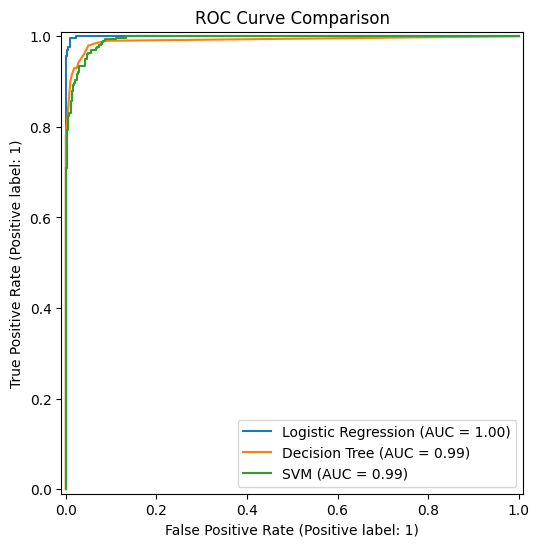

In [ ]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(8, 6))

for model, probs, title in zip(
    [lr, dt, svm],
    [lr_probs, y_prob_dt, y_prob_svm],
    ['Logistic Regression', 'Decision Tree', 'SVM']):
    RocCurveDisplay.from_predictions(y_test, probs, ax=ax, name=title)

ax.set_title('ROC Curve Comparison')
plt.show()

In the ROC Curve comparison above, the visual highlights the tradeoff between true positive rate and false positive rate across all three models. All three models perform strongly, with Logistic Regression achieving a perfect AUC of 1.00 and both Decision Tree and SVM at 0.99. The curves hugging the top-left corner indicates that all models are highly effective at distinguishing between patients with and without heart disease across different classification thresholds.

**Visual 2: Confusion Matrix**

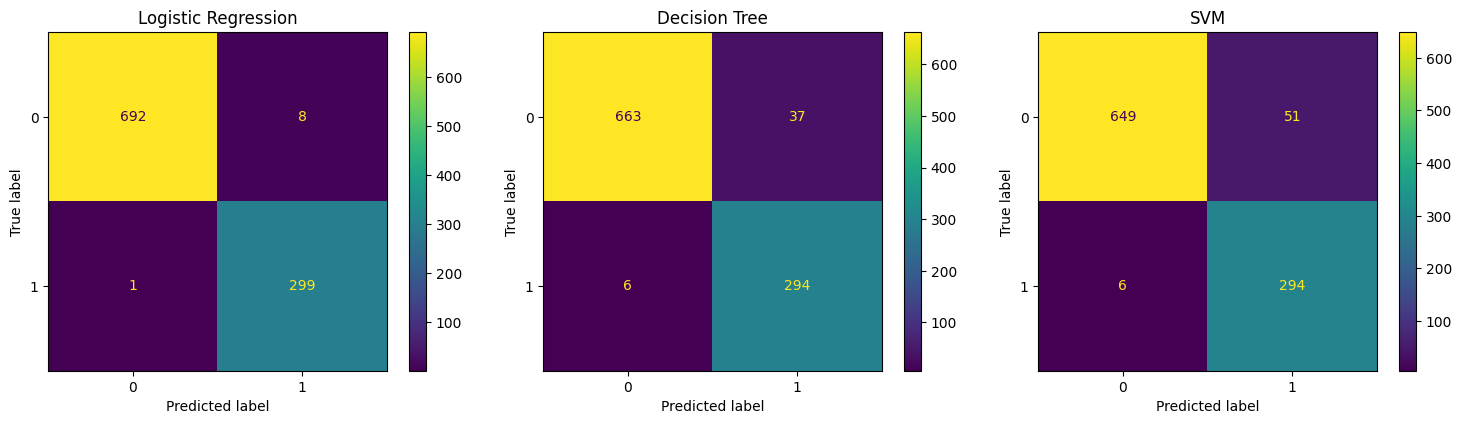

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, model, preds, title in zip(axes,
    [lr, dt, svm],
    [lr_preds, y_pred_dt, y_pred_svm],
    ['Logistic Regression', 'Decision Tree', 'SVM']):
    ConfusionMatrixDisplay.from_predictions(y_test, preds, ax=ax)
    ax.set_title(title)

plt.tight_layout()
plt.show()

In the confusion matrices, each model showcases correct and incorrect predictions. Logistic Regression has the fewest false negatives (1), meaning it almost never misses an actual heart disease case, the most critical error in a healthcare context. The Decision Tree and SVM both produce 6 false negatives and notably more false positives, trading some precision for slightly lower recall on the negative class. Given that false negatives represent missed diagnoses, Logistic Regression's performance is particularly favorable despite being the simplest model.

#Current Challenges

- Unusually High Model Performance All four of our models achieve ROC-AUC scores above 0.99, with logistic regression reaching 0.9996 and random forest at 0.9961. While strong performance is the goal, scores this high on a medical prediction task are uncommon in practice. The most likely reason is that our dataset is synthetic and built with very clean, easy-to-separate patterns that do not reflect the messiness of real patient data. This means our results may not hold up as well if applied to real clinical records.
- Possible Feature Leakage Some of our features, specifically chest_pain, diabetes, and stroke, are so closely linked to heart disease that they may be giving the model an unfair shortcut rather than helping it learn a real clinical pattern. This could be part of why our logistic regression catches 100% of positive cases. We have not tested this yet by removing those features and retraining, so we cannot say for certain whether the model is learning something meaningful or just following a shortcut in the data.
- Class Imbalance Our dataset has about 70% of patients without heart disease and 30% with it. We handled this using stratified splitting and class_weight='balanced' across all models. Even so, the imbalance affects some of our results. For example, SVM only achieves 85% precision on the positive class, meaning about 15 out of every 100 patients it flags do not actually have heart disease. In a real medical setting, that kind of tradeoff would need to be thought through carefully.
- Limited Fairness Evaluation Our gender subgroup analysis shows very similar heart disease rates across groups, around 30.41% (male) and 29.55% (female), which suggests our dataset is balanced by gender. However, our dataset does not include race, ethnicity, or socioeconomic status. Those are the exact variables tied to our project's main goal, since our project is about reducing the kinds of bias that have historically affected medical diagnosis in the US. Without those variables, we cannot fully check whether our model would work fairly for the groups most affected by that bias.

# Plan for Completion

- Run a Feature Ablation Test: We plan to retrain our logistic regression model without the features most likely to be shortcuts (chest_pain, diabetes, stroke) and compare results to the full model. If performance drops a lot, that tells us the model was relying on those features too heavily. If performance stays strong, that gives us more confidence that the model is learning something genuinely useful.
- Finalize the Fairness Discussion: We will add a clear section addressing what our fairness evaluation can and cannot say. Our gender subgroup results are a good starting point, but we will be upfront that the missing demographic variables mean we cannot fully meet our original project goal of testing for medical bias. This is a data limitation, not a modeling one, and being honest about it is part of doing this responsibly.
- Final Model Selection: We plan to use logistic regression as our final model. It has the highest recall on the positive class at 100%, meaning it missed zero actual heart disease cases in our test set. It also leads on accuracy at 99.1% and ROC-AUC at 0.9996. On top of that, it is the easiest of our four models to interpret since its coefficients show exactly how each feature is influencing the prediction, which fits our goal of making predictions that are transparent and clinically grounded. Random Forest gets close on some metrics but is harder to explain.